# MC, TD and multi-step prediction against known values

An unbiased random walk has nineteen interior states and terminal rewards -1 and +1. Its exact undiscounted value is linear. Methods share each sampled trajectory, while analytical values are used only to measure error. TD(lambda) uses accumulating traces; Monte Carlo updates every visit.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/decision_lab").is_dir()
sys.path.insert(0, str(ROOT / "src"))


def read(path):
    return json.loads((ROOT / path).read_text())

## Analytical Bellman check

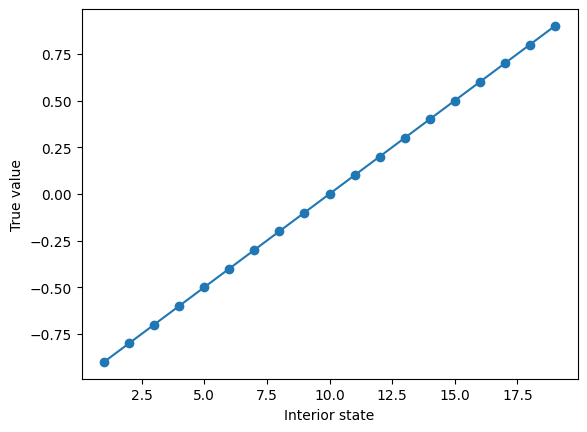

In [2]:
true = np.linspace(-1.0, 1.0, 21)
assert np.allclose(true[1:-1], 0.5 * (true[:-2] + true[2:]))
plt.plot(np.arange(1, 20), true[1:-1], "o-")
plt.xlabel("Interior state")
plt.ylabel("True value")
plt.show()

## Every prediction seed

monte_carlo final mean 0.38723211074604436 fit SD 0.13375946891663007
td0 final mean 0.04420902641679119 fit SD 0.015316399727390231
nstep5 final mean 0.09063911875229895 fit SD 0.030630190289853455
td_lambda final mean 0.08731745716445022 fit SD 0.030117193164868092


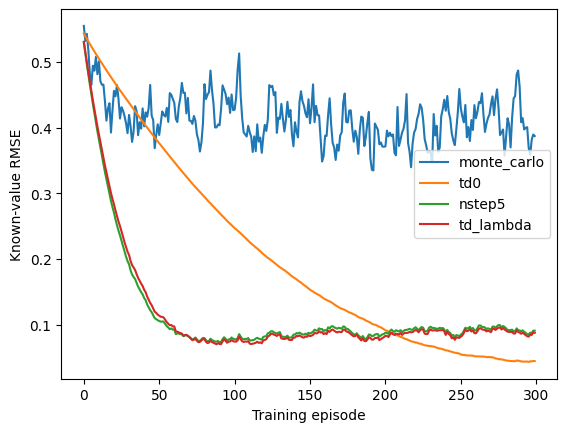

In [3]:
data = np.load(ROOT / "assets/source_data/lectures/prediction.npz")
for name in data.files:
    rms = data[name]
    assert rms.shape == (30, 300)
    print(name, "final mean", rms[:, -1].mean(), "fit SD", rms[:, -1].std(ddof=1))
    plt.plot(rms.mean(0), label=name)
plt.xlabel("Training episode")
plt.ylabel("Known-value RMSE")
plt.legend()
plt.show()

## Preset step sizes are not method rankings

In [4]:
read("results/reference/lectures/metrics.json")["prediction"]["protocol"]

'Identical sampled trajectories shared across methods within each seed; 19 interior states, unbiased random walk, terminal rewards -1/+1, gamma 1, alpha .05, accumulating TD(lambda=.8). Every-visit Monte Carlo; online n-step backups over recorded trajectories. Analytical values used only for error measurement.'

Full fits: `decision-lab lectures --seed 0` (repeat seeds 1 and 2 where applicable). See [protocol](../docs/protocol.md), [results](../docs/results.md) and [references](../docs/references.md). These cells are numerical checks and evidence readers, not replacement training budgets.